In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# helper to check
def is_diag_dom(a, b, c):
    n = b.size
    off = np.zeros_like(b, dtype=float)
    if n == 1:
        off[0] = 0.0
    elif n == 2:
        off[0] = abs(c[0])
        off[1] = abs(a[0])
    else:
        off[0] = abs(c[0])
        off[1:-1] = np.abs(a[:-1]) + np.abs(c[1:])
        off[-1] = abs(a[-1])
    return np.all(np.abs(b) >= off)

In [52]:
def fftfd( x: np.ndarray, y: np.ndarray, z: np.ndarray) -> np.ndarray:
    """
    Compute the 3D Poisson equation using the FFT2D-FD method.
    FFT2D for x-direction, y-direction and central finite differences for z-direction.

    Parameters
    ----------
    f : array_like
        Input array of shape (Nx, Ny, Nz) containing the right-hand side of the Poisson equation.
    x : array_like
        Array of shape (Nx,) containing the x coordinates.
    y : array_like
        Array of shape (Ny,) containing the y coordinates.
    z : array_like
        Array of shape (Nz,) containing the z coordinates.

    Returns
    -------
    ndarray (Nx, Ny, Nz)
        Approximation of the Poisson equation.
    """
    Nx, Ny, Nz = x.shape[0], y.shape[0], z.shape[0]
    dz = z[1] - z[0]
    x_max = x[-1] # Max x value
    y_max = y[-1] # Max y value
    p_top = np.zeros((Nx, Ny)) # Top boundary condition p = 0
    rr = np.fft.fftfreq(Nx - 1) * (Nx - 1)
    ss = np.fft.fftfreq(Ny - 1) * (Ny - 1)
    # Scale frequencies for any domain
    kx = 2 * np.pi * rr * dz / x_max
    ky = 2 * np.pi * ss * dz / y_max
    conds = np.empty((Nx - 1, Ny - 1), dtype=float)
    diagonal_dominance = np.empty((Nx - 1, Ny - 1), dtype=bool)
    # mats = []
    # Solve the system for each gamma
    for r in range(Nx - 1):
        # tmp = []
        for s in range(Ny - 1):
            # Compute gamma
            gamma_rs = - 2 - kx[r] ** 2 - ky[s] ** 2
            # Create RHS of system
            # Create A in the system. Only keep diagonals of matrix
            a = np.ones(Nz - 2) / dz ** 2
            b = np.ones(Nz - 1) * gamma_rs / dz ** 2
            c = np.ones(Nz - 2) / dz ** 2
            # Fix first coefficients
            c[0] = (2 + 0.5 * gamma_rs) / dz
            b[0] = -1 / dz
            # Solve system A P_k = F_k
            # Built A matrix using diagonals
            # diagonals = [a, b, c]
            # Build dense tridiagonal matrix A (size Nz-1) using NumPy (avoid extra imports)
            # n = Nz - 1
            A = np.diag(b) + np.diag(a, -1) + np.diag(c, 1)
            try:
                conds[r, s] = np.linalg.cond(A)
            except np.linalg.LinAlgError:
                conds[r, s] = np.inf
            # Check if A is diagonally dominant
            diagonal_dominance[r, s] = is_diag_dom(a, b, c)
    return conds, diagonal_dominance

In [61]:
# Nx, Ny, Nz = 256, 256, 128
Nx, Ny, Nz = 32, 32, 16
x_min, x_max = -200, 400
y_min, y_max = -200, 400
z_min, z_max = 0, 20
x = np.linspace(x_min, x_max, Nx)
y = np.linspace(y_min, y_max, Ny)
z = np.linspace(z_min, z_max, Nz)
conds, di = fftfd(x, y, z)

20.863274336794163 375.0778935323892 [ True]


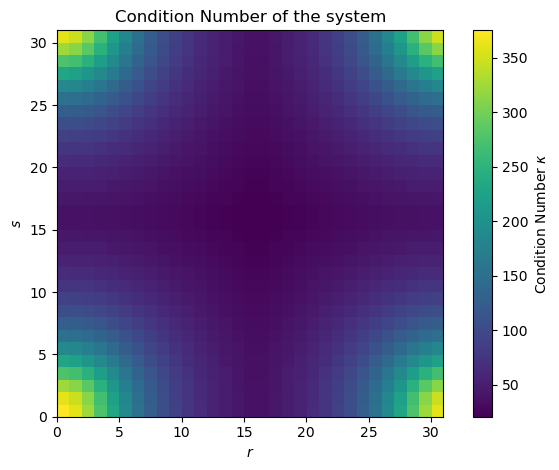

In [62]:
plt.imshow(conds.T, origin='lower', extent=(0, Nx - 1, 0, Ny - 1), interpolation='nearest')
plt.colorbar(label=r'Condition Number $\kappa$')
plt.xlabel(r'$r$')
plt.ylabel(r'$s$')
plt.title('Condition Number of the system')
# plt.show()
plt.tight_layout()
plt.savefig(f'condition_number_{Nx}x{Ny}x{Nz}.pdf', dpi=300, transparent=True)
print(np.min(conds), np.max(conds), np.unique(di))

In [ ]:
Nx, Ny, Nz = 256, 256, 128
x_min, x_max = -200, 400
y_min, y_max = -200, 400
z_min, z_max = 0, 20
x = np.linspace(x_min, x_max, Nx)
y = np.linspace(y_min, y_max, Ny)
z = np.linspace(z_min, z_max, Nz)

conds_h, di_h = fftfd(x, y, z)

84.33537934931434 33540.99531619837 [ True]


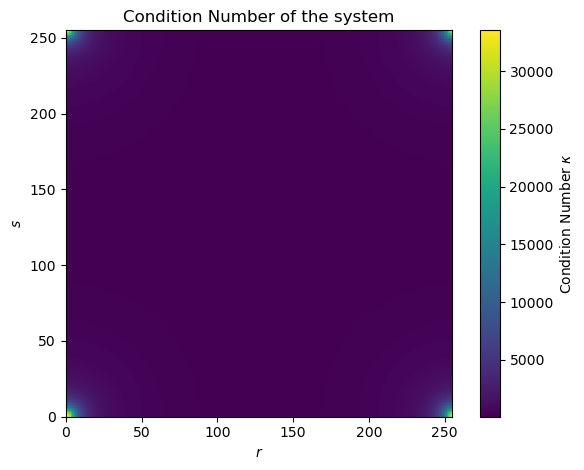

In [63]:
# plt.figure(figsize=(12, 6))
Nx, Ny, Nz = 256, 256, 128
plt.imshow(conds_h.T, origin='lower', extent=(0, Nx - 1, 0, Ny - 1), interpolation='nearest')
plt.colorbar(label=r'Condition Number $\kappa$')
plt.xlabel(r'$r$')
plt.ylabel(r'$s$')
plt.title('Condition Number of the system')
plt.tight_layout()
# plt.show()
plt.savefig(f'condition_number_{Nx}x{Ny}x{Nz}.pdf', dpi=300, transparent=True)
print(np.min(conds_h), np.max(conds_h), np.unique(di_h))